In [2]:

%pip install -q pycbc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 108.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 MB 18.5 MB/s eta 0:00:00


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

try:
    import pycbc
    print("PyCBC:", pycbc.__version__)
except Exception as e:
    print("PyCBC unavailable:", repr(e))

try:
    import gwpy
    print("GWpy:", gwpy.__version__)
except Exception as e:
    print("GWpy unavailable:", repr(e))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
PyCBC: 2.11.0
GWpy: 4.1.0


In [3]:

from pycbc.catalog import Merger

event = Merger("GW150914")

h1 = event.strain("H1")
l1 = event.strain("L1")

for detector, data in [("H1", h1), ("L1", l1)]:
    print(f"\n{detector}")
    print("Number of samples:", len(data))
    print("Sampling rate:", float(data.sample_rate), "Hz")
    print("Duration:", float(data.duration), "seconds")
    print("Start time:", data.start_time)
    print("End time:", data.end_time)


/usr/lib/python3.13/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)



H1
Number of samples: 131072
Sampling rate: 4096.0 Hz
Duration: 32.0 seconds
Start time: 1126259447.0
End time: 1126259479.0

L1
Number of samples: 131072
Sampling rate: 4096.0 Hz
Duration: 32.0 seconds
Start time: 1126259447.0
End time: 1126259479.0


In [4]:

for detector, data in {"H1": h1, "L1": l1}.items():
    values = np.asarray(data)

    print(f"\n{detector} Data Quality")

    print("Number of samples:", len(values))
    print("Non-finite samples:", np.sum(~np.isfinite(values)))
    print("Minimum strain:", np.min(values))
    print("Maximum strain:", np.max(values))
    print("Mean strain:", np.mean(values))
    print("Standard deviation:", np.std(values))



H1 Data Quality
Number of samples: 131072
Non-finite samples: 0
Minimum strain: -7.04466594316914e-19
Maximum strain: 7.706262192395323e-19
Mean strain: -3.7594485871462737e-23
Standard deviation: 2.18086907234423e-19

L1 Data Quality
Number of samples: 131072
Non-finite samples: 0
Minimum strain: -1.8697138664246853e-18
Maximum strain: -4.600351113064713e-20
Mean strain: -1.0522364772927026e-18
Standard deviation: 2.308974005228782e-19


In [5]:

import numpy as np
from pycbc.filter import highpass_fir

h1_hp = highpass_fir(h1, 15.0, 8)
l1_hp = highpass_fir(l1, 15.0, 8)

for detector, data in {"H1": h1_hp, "L1": l1_hp}.items():
    values = np.asarray(data)

    print(f"\n{detector} after high-pass filtering")
    print("Mean strain:", np.mean(values))
    print("Standard deviation:", np.std(values))
    print("Minimum strain:", np.min(values))
    print("Maximum strain:", np.max(values))
    print("Non-finite samples:", np.sum(~np.isfinite(values)))



H1 after high-pass filtering
Mean strain: -3.9974988324337934e-23
Standard deviation: 2.0422449892830927e-19
Minimum strain: -6.614375974673471e-19
Maximum strain: 7.238756962049024e-19
Non-finite samples: 0

L1 after high-pass filtering
Mean strain: -9.848527537357787e-19
Standard deviation: 2.1673734204661062e-19
Minimum strain: -1.751953904203739e-18
Maximum strain: 0.0
Non-finite samples: 0


In [6]:

from pycbc.filter import highpass

h1_hp = highpass(h1, 15.0, filter_order=8)
l1_hp = highpass(l1, 15.0, filter_order=8)

for detector, data in {"H1": h1_hp, "L1": l1_hp}.items():
    values = np.asarray(data)

    print(f"\n{detector} after high-pass filtering")
    print("Mean strain:", np.mean(values))
    print("Standard deviation:", np.std(values))
    print("Minimum strain:", np.min(values))
    print("Maximum strain:", np.max(values))
    print("Non-finite samples:", np.sum(~np.isfinite(values)))



H1 after high-pass filtering
Mean strain: 2.564153703927553e-24
Standard deviation: 1.747739147315936e-20
Minimum strain: -6.622684927818125e-20
Maximum strain: 7.301187293833099e-20
Non-finite samples: 0

L1 after high-pass filtering
Mean strain: 2.2723387813860293e-23
Standard deviation: 4.407237513220291e-20
Minimum strain: -1.6757949696238532e-19
Maximum strain: 4.4089304448541725e-19
Non-finite samples: 0


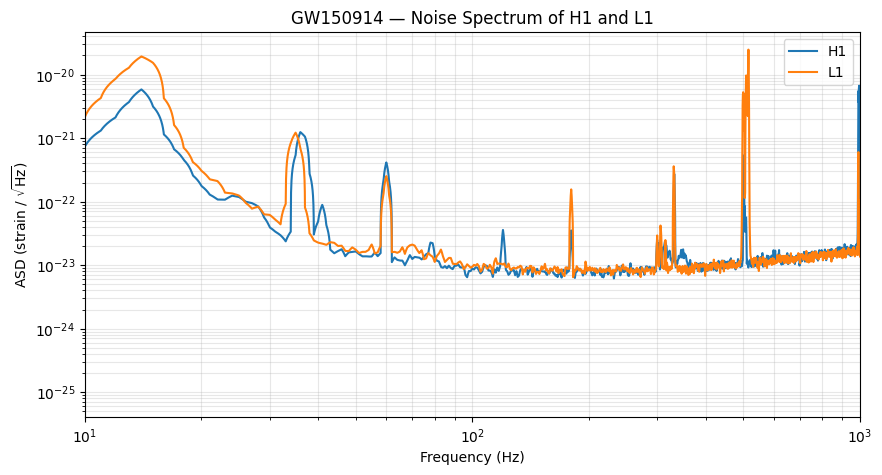

In [10]:

from pycbc.psd import welch, interpolate

psd_h1 = interpolate(welch(h1_hp), 1.0 / float(h1_hp.duration))
psd_l1 = interpolate(welch(l1_hp), 1.0 / float(l1_hp.duration))

freq_h1 = np.arange(len(psd_h1)) * float(psd_h1.delta_f)
freq_l1 = np.arange(len(psd_l1)) * float(psd_l1.delta_f)

plt.figure(figsize=(10, 5))

plt.loglog(
    freq_h1[1:],
    np.sqrt(np.asarray(psd_h1)[1:]),
    label="H1"
)
plt.loglog(
    freq_l1[1:],
    np.sqrt(np.asarray(psd_l1)[1:]),
    label="L1"
)

plt.xlim(10, 1000)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"ASD (strain / $\sqrt{\mathrm{Hz}}$)")
plt.title("GW150914 — Noise Spectrum of H1 and L1")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


In [11]:

from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter

event_time = 1126259462.43

hp, hc = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40,
    mass2=32,
    f_lower=20.0,
    delta_f=1.0 / float(h1_hp.duration)
)

hp.resize(len(h1_hp) // 2 + 1)

snr_h1 = matched_filter(
    hp, h1_hp, psd=psd_h1,
    low_frequency_cutoff=20.0
)

snr_l1 = matched_filter(
    hp, l1_hp, psd=psd_l1,
    low_frequency_cutoff=20.0
)

snr_h1 = snr_h1[len(snr_h1)//4: 3*len(snr_h1)//4]
snr_l1 = snr_l1[len(snr_l1)//4: 3*len(snr_l1)//4]

for detector, snr in [("H1", snr_h1), ("L1", snr_l1)]:
    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))

    mask = (
        (times >= event_time - 0.2) &
        (times <= event_time + 0.2)
    )

    if not np.any(mask):
        print(f"{detector}: no samples in the selected time window")
        continue

    indices = np.flatnonzero(mask)
    peak_idx = indices[np.argmax(values[indices])]

    print(f"\n{detector}")
    print("Peak |SNR|:", float(values[peak_idx]))
    print("Peak time (GPS):", float(times[peak_idx]))
    print("Time offset (s):", float(times[peak_idx] - event_time))



H1
Peak |SNR|: 18.756362845717913
Peak time (GPS): 1126259462.4282227
Time offset (s): -0.0017774105072021484

L1
Peak |SNR|: 13.998621196332405
Peak time (GPS): 1126259462.4211426
Time offset (s): -0.008857488632202148


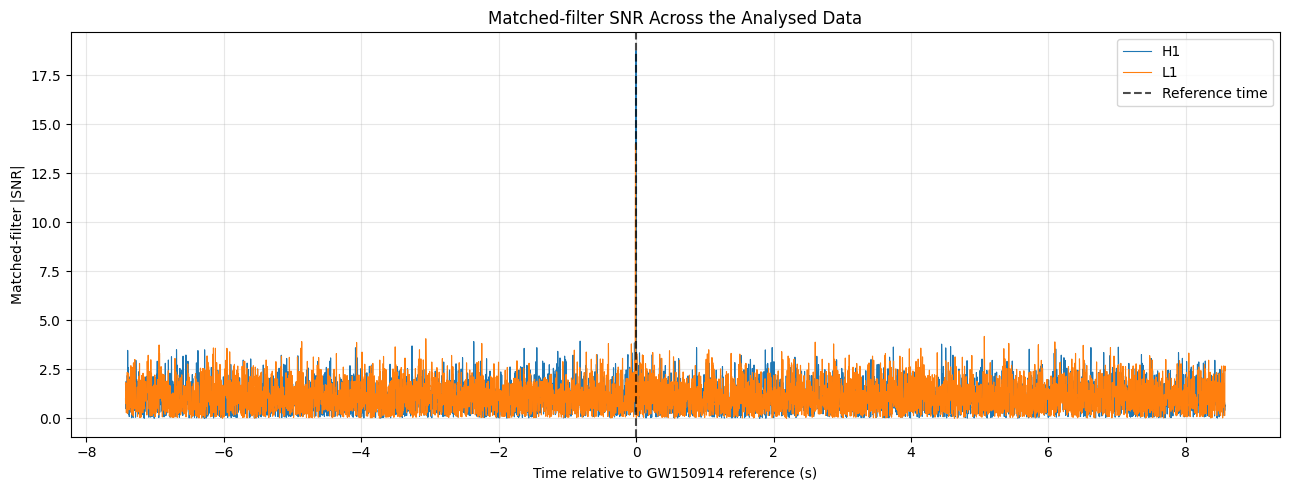

In [12]:

plt.figure(figsize=(13, 5))

for detector, snr in [("H1", snr_h1), ("L1", snr_l1)]:
    relative_time = np.asarray(snr.sample_times) - event_time
    snr_values = np.abs(np.asarray(snr))

    plt.plot(
        relative_time,
        snr_values,
        label=detector,
        linewidth=0.8
    )

plt.axvline(
    0,
    color="black",
    linestyle="--",
    alpha=0.7,
    label="Reference time"
)

plt.xlabel("Time relative to GW150914 reference (s)")
plt.ylabel("Matched-filter |SNR|")
plt.title("Matched-filter SNR Across the Analysed Data")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [13]:

for detector, snr in [("H1", snr_h1), ("L1", snr_l1)]:
    relative_time = np.asarray(snr.sample_times) - event_time
    snr_values = np.abs(np.asarray(snr))

    on_source = np.abs(relative_time) <= 0.1
    off_source = ~on_source

    on_indices = np.flatnonzero(on_source)
    peak_index = on_indices[np.argmax(snr_values[on_source])]

    peak_snr = snr_values[peak_index]
    peak_time = relative_time[peak_index]

    background = snr_values[off_source]
    max_background = np.max(background)
    percentile_99 = np.percentile(background, 99)
    median_background = np.median(background)

    print(f"\n{detector}")
    print(f"Peak SNR near event: {peak_snr:.3f}")
    print(f"Peak time offset: {peak_time:.6f} s")
    print(f"Maximum off-source SNR: {max_background:.3f}")
    print(f"99th percentile off-source SNR: {percentile_99:.3f}")
    print(f"Median off-source SNR: {median_background:.3f}")
    print(f"Peak / max background: {peak_snr / max_background:.2f}")



H1
Peak SNR near event: 18.756
Peak time offset: -0.001777 s
Maximum off-source SNR: 3.943
99th percentile off-source SNR: 2.938
Median off-source SNR: 1.144
Peak / max background: 4.76

L1
Peak SNR near event: 13.999
Peak time offset: -0.008857 s
Maximum off-source SNR: 4.184
99th percentile off-source SNR: 3.064
Median off-source SNR: 1.175
Peak / max background: 3.35


In [14]:

from pycbc.detector import Detector

def get_peak_near_event(snr, event_time, window=0.1):
    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))

    mask = np.abs(times - event_time) <= window
    indices = np.flatnonzero(mask)

    if len(indices) == 0:
        raise ValueError("No SNR samples found near the event time.")

    peak_idx = indices[np.argmax(values[indices])]
    return float(times[peak_idx]), float(values[peak_idx])

t_h1, rho_h1 = get_peak_near_event(snr_h1, event_time)
t_l1, rho_l1 = get_peak_near_event(snr_l1, event_time)

observed_delay = abs(t_h1 - t_l1)

max_delay = Detector("H1").light_travel_time_to_detector(
    Detector("L1")
)

print(f"H1 peak time: {t_h1:.6f} GPS")
print(f"L1 peak time: {t_l1:.6f} GPS")
print(f"Observed peak-time difference: {observed_delay * 1000:.3f} ms")
print(f"Maximum light-travel time: {max_delay * 1000:.3f} ms")
print("Within physical timing bound:", observed_delay <= max_delay)


H1 peak time: 1126259462.428223 GPS
L1 peak time: 1126259462.421143 GPS
Observed peak-time difference: 7.080 ms
Maximum light-travel time: 10.013 ms
Within physical timing bound: True


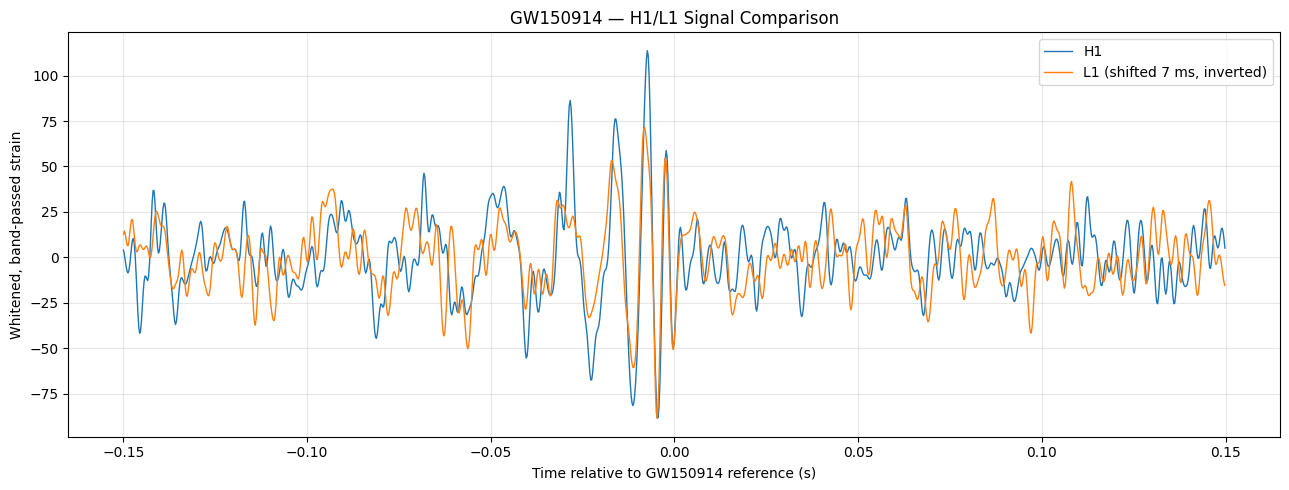

In [15]:

from pycbc.filter import highpass_fir, lowpass_fir

white_h1 = (h1_hp.to_frequencyseries() / psd_h1**0.5).to_timeseries()
white_l1 = (l1_hp.to_frequencyseries() / psd_l1**0.5).to_timeseries()

smooth_h1 = lowpass_fir(highpass_fir(white_h1, 35.0, 8), 300.0, 8)
smooth_l1 = lowpass_fir(highpass_fir(white_l1, 35.0, 8), 300.0, 8)


shift_samples = round(0.007 / float(smooth_l1.delta_t))
l1_aligned = -np.roll(np.asarray(smooth_l1), shift_samples)

times = np.asarray(smooth_h1.sample_times) - event_time
h1_values = np.asarray(smooth_h1)
l1_times = np.asarray(smooth_l1.sample_times) - event_time

window = (times >= -0.15) & (times <= 0.15)

plt.figure(figsize=(13, 5))
plt.plot(times[window], h1_values[window], label="H1", linewidth=1)
plt.plot(l1_times[window], l1_aligned[window], label="L1 (shifted 7 ms, inverted)", linewidth=1)

plt.xlabel("Time relative to GW150914 reference (s)")
plt.ylabel("Whitened, band-passed strain")
plt.title("GW150914 — H1/L1 Signal Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Best lag: 7.324 ms
Maximum correlation: 0.6699


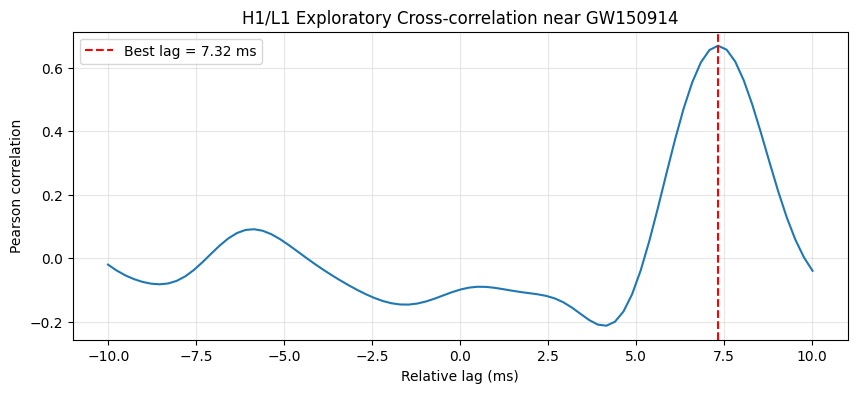

In [16]:

from scipy.stats import pearsonr

rel_h1 = np.asarray(smooth_h1.sample_times) - event_time
rel_l1 = np.asarray(smooth_l1.sample_times) - event_time

window_h1 = (rel_h1 >= -0.1) & (rel_h1 <= 0.1)
window_l1 = (rel_l1 >= -0.1) & (rel_l1 <= 0.1)

x = np.asarray(smooth_h1)[window_h1]
y = -np.asarray(smooth_l1)[window_l1]

dt = float(smooth_h1.delta_t)
max_lag = int(round(0.010 / dt))

results = []

for lag in range(-max_lag, max_lag + 1):
    if lag > 0:
        a, b = x[lag:], y[:-lag]
    elif lag < 0:
        a, b = x[:lag], y[-lag:]
    else:
        a, b = x, y

    corr, _ = pearsonr(a, b)
    results.append((lag * dt * 1000, corr))

best_lag_ms, best_corr = max(results, key=lambda item: item[1])

print(f"Best lag: {best_lag_ms:.3f} ms")
print(f"Maximum correlation: {best_corr:.4f}")

lags_ms, correlations = np.array(results).T

plt.figure(figsize=(10, 4))
plt.plot(lags_ms, correlations)
plt.axvline(best_lag_ms, color="red", linestyle="--",
            label=f"Best lag = {best_lag_ms:.2f} ms")
plt.xlabel("Relative lag (ms)")
plt.ylabel("Pearson correlation")
plt.title("H1/L1 Exploratory Cross-correlation near GW150914")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [17]:

from scipy.stats import pearsonr

dt = float(smooth_h1.delta_t)
max_lag = int(round(0.010 / dt))
half_window = 0.1

def best_window_correlation(center):
    rel_h1 = np.asarray(smooth_h1.sample_times) - event_time
    rel_l1 = np.asarray(smooth_l1.sample_times) - event_time

    mask_h1 = (
        (rel_h1 >= center - half_window) &
        (rel_h1 <= center + half_window)
    )
    mask_l1 = (
        (rel_l1 >= center - half_window) &
        (rel_l1 <= center + half_window)
    )

    x = np.asarray(smooth_h1)[mask_h1]
    y = -np.asarray(smooth_l1)[mask_l1]

    if len(x) != len(y) or len(x) <= 2 * max_lag:
        return np.nan, np.nan

    results = []

    for lag in range(-max_lag, max_lag + 1):
        if lag > 0:
            a, b = x[lag:], y[:-lag]
        elif lag < 0:
            a, b = x[:lag], y[-lag:]
        else:
            a, b = x, y

        corr, _ = pearsonr(a, b)
        results.append((lag * dt * 1000, corr))

    return max(results, key=lambda item: item[1])

centers = np.arange(-7.0, 7.01, 0.5)
centers = centers[np.abs(centers) >= 0.5]

control_results = []

for center in centers:
    lag_ms, corr = best_window_correlation(center)
    if np.isfinite(corr):
        control_results.append((center, lag_ms, corr))

control_corr = np.array([row[2] for row in control_results])

event_lag_ms, event_corr = best_window_correlation(0.0)

print("On-source correlation:", round(event_corr, 4))
print("On-source best lag (ms):", round(event_lag_ms, 3))
print("Off-source windows:", len(control_corr))

print("Off-source median:", round(np.median(control_corr), 4))
print("Off-source 95th percentile:",
      round(np.percentile(control_corr, 95), 4))
print("Maximum off-source correlation:",
      round(np.max(control_corr), 4))
print("Off-source windows >= on-source:",
      int(np.sum(control_corr >= event_corr)))


On-source correlation: 0.6699
On-source best lag (ms): 7.324
Off-source windows: 28
Off-source median: 0.1621
Off-source 95th percentile: 0.2264
Maximum off-source correlation: 0.2499
Off-source windows >= on-source: 0


In [18]:

%pip install -q gwpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 31.4 MB/s eta 0:00:00


In [30]:
from gwpy.timeseries import TimeSeries

l1_long = TimeSeries.fetch_open_data(
    "L1",
    1126257415,
    1126261511,
    sample_rate=4096,
    cache=True
)

print(" L1 loaded successfully")
print("Samples:", len(l1_long))
print("Duration:", l1_long.duration)
print("Duration:", h1_long.duration)

 L1 loaded successfully
Samples: 16777216
Duration: 4096.0 s
Duration: 4096.0 s


In [31]:

for detector, data in {"H1": h1_long, "L1": l1_long}.items():
    values = np.asarray(data)

    sampling_rate = data.sample_rate.to_value("Hz")
    duration = data.duration.to_value("s")
    start_time = data.t0.to_value("s")
    end_time = start_time + duration

    print(f"\n{detector} — Long Data Validation")
    print("Samples:", len(values))
    print("Sampling rate (Hz):", sampling_rate)
    print("Duration (seconds):", duration)
    print("Start GPS:", start_time)
    print("End GPS:", end_time)
    print("Non-finite samples:", int(np.sum(~np.isfinite(values))))



H1 — Long Data Validation
Samples: 16777216
Sampling rate (Hz): 4096.0
Duration (seconds): 4096.0
Start GPS: 1126257415.0
End GPS: 1126261511.0
Non-finite samples: 0

L1 — Long Data Validation
Samples: 16777216
Sampling rate (Hz): 4096.0
Duration (seconds): 4096.0
Start GPS: 1126257415.0
End GPS: 1126261511.0
Non-finite samples: 0


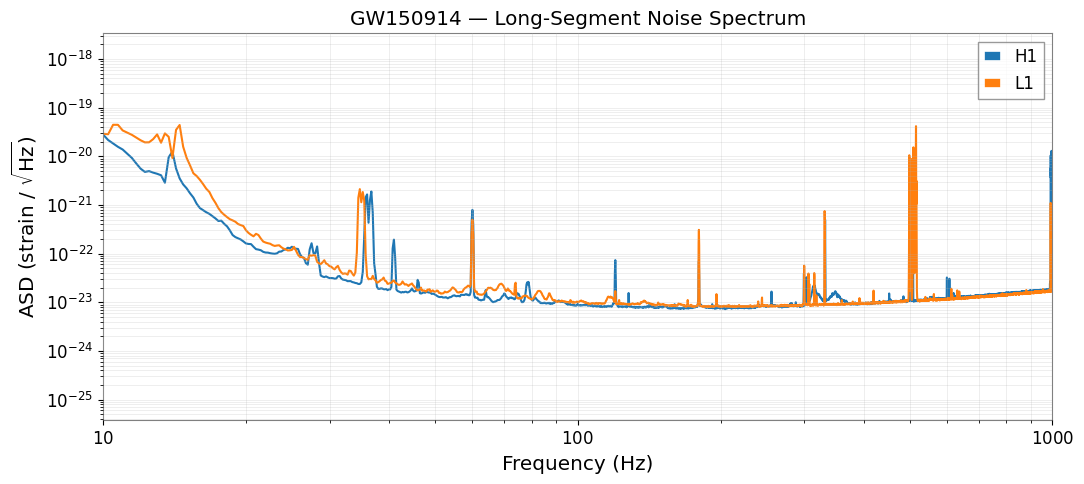

H1 PSD frequency resolution: 0.25 Hz
L1 PSD frequency resolution: 0.25 Hz


In [32]:

from pycbc.types import TimeSeries as PyCBCTimeSeries
from pycbc.psd import welch
import numpy as np
import matplotlib.pyplot as plt

h1_long_pc = PyCBCTimeSeries(
    np.asarray(h1_long),
    delta_t=1.0 / 4096,
    epoch=h1_long.t0.to_value("s")
)

l1_long_pc = PyCBCTimeSeries(
    np.asarray(l1_long),
    delta_t=1.0 / 4096,
    epoch=l1_long.t0.to_value("s")
)

segment_length = 4 * 4096
segment_stride = 2 * 4096

psd_h1_long = welch(
    h1_long_pc,
    seg_len=segment_length,
    seg_stride=segment_stride,
    avg_method="median"
)

psd_l1_long = welch(
    l1_long_pc,
    seg_len=segment_length,
    seg_stride=segment_stride,
    avg_method="median"
)

freq_h1 = np.arange(len(psd_h1_long)) * psd_h1_long.delta_f
freq_l1 = np.arange(len(psd_l1_long)) * psd_l1_long.delta_f

plt.figure(figsize=(11, 5))

plt.loglog(
    freq_h1[1:],
    np.sqrt(np.asarray(psd_h1_long)[1:]),
    label="H1"
)
plt.loglog(
    freq_l1[1:],
    np.sqrt(np.asarray(psd_l1_long)[1:]),
    label="L1"
)

plt.xlim(10, 1000)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"ASD (strain / $\sqrt{\mathrm{Hz}}$)")
plt.title("GW150914 — Long-Segment Noise Spectrum")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("H1 PSD frequency resolution:", psd_h1_long.delta_f, "Hz")
print("L1 PSD frequency resolution:", psd_l1_long.delta_f, "Hz")


In [33]:

event_time = 1126259462.4

h1_event = h1_long.crop(event_time - 16, event_time + 16)
l1_event = l1_long.crop(event_time - 16, event_time + 16)

for detector, data in {"H1": h1_event, "L1": l1_event}.items():
    print(f"\n{detector} — Event Segment")
    print("Samples:", len(data))
    print("Sampling rate (Hz):", data.sample_rate.to_value("Hz"))
    print("Duration (s):", data.duration.to_value("s"))
    print("Start GPS:", data.t0.to_value("s"))
    print("Non-finite samples:", int(np.sum(~np.isfinite(data.value))))



H1 — Event Segment
Samples: 131072
Sampling rate (Hz): 4096.0
Duration (s): 32.0
Start GPS: 1126259446.3999023
Non-finite samples: 0

L1 — Event Segment
Samples: 131072
Sampling rate (Hz): 4096.0
Duration (s): 32.0
Start GPS: 1126259446.3999023
Non-finite samples: 0


In [34]:

from pycbc.types import TimeSeries as PyCBCTimeSeries
from pycbc.psd import interpolate


h1_event_pc = PyCBCTimeSeries(
    np.asarray(h1_event),
    delta_t=1.0 / 4096,
    epoch=h1_event.t0.to_value("s")
)

l1_event_pc = PyCBCTimeSeries(
    np.asarray(l1_event),
    delta_t=1.0 / 4096,
    epoch=l1_event.t0.to_value("s")
)


h1_event_hp = highpass(h1_event_pc, 15.0, filter_order=8)
l1_event_hp = highpass(l1_event_pc, 15.0, filter_order=8)


target_delta_f = 1.0 / 32.0

psd_h1_event = interpolate(psd_h1_long, target_delta_f)
psd_l1_event = interpolate(psd_l1_long, target_delta_f)

for detector, data, psd in [
    ("H1", h1_event_hp, psd_h1_event),
    ("L1", l1_event_hp, psd_l1_event)
]:
    print(f"\n{detector}")
    print("Data samples:", len(data))
    print("Data duration (s):", len(data) * float(data.delta_t))
    print("PSD frequency resolution (Hz):", float(psd.delta_f))
    print("PSD frequency bins:", len(psd))
    print("Non-finite data samples:",
          int(np.sum(~np.isfinite(np.asarray(data)))))



H1
Data samples: 131072
Data duration (s): 32.0
PSD frequency resolution (Hz): 0.03125
PSD frequency bins: 65537
Non-finite data samples: 0

L1
Data samples: 131072
Data duration (s): 32.0
PSD frequency resolution (Hz): 0.03125
PSD frequency bins: 65537
Non-finite data samples: 0


In [35]:

from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter

event_time = 1126259462.4

def calculate_event_snr(strain, psd, detector_name):
    delta_f = 1.0 / strain.duration

    hp, hc = get_fd_waveform(
        approximant="IMRPhenomD",
        mass1=40,
        mass2=32,
        f_lower=20.0,
        delta_f=delta_f
    )

    hp.resize(len(strain) // 2 + 1)

    snr = matched_filter(
        hp,
        strain,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    snr = snr[len(snr)//4 : 3*len(snr)//4]

    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))

    on_source = np.abs(times - event_time) <= 0.1
    indices = np.flatnonzero(on_source)

    if len(indices) == 0:
        raise ValueError(f"{detector_name}: no samples near event time")

    peak_idx = indices[np.argmax(values[indices])]

    peak_snr = values[peak_idx]
    peak_time = times[peak_idx]

    off_source = np.abs(times - event_time) > 0.1
    background = values[off_source]

    print(f"\n{detector_name}")
    print(f"Peak SNR near event: {peak_snr:.3f}")
    print(f"Peak time (GPS): {peak_time:.6f}")
    print(f"Peak offset (ms): {(peak_time - event_time)*1000:.3f}")
    print(f"Maximum off-source SNR: {np.max(background):.3f}")
    print(f"99th percentile off-source SNR: {np.percentile(background, 99):.3f}")

    return snr

snr_h1_long_psd = calculate_event_snr(
    h1_event_hp, psd_h1_event, "H1"
)

snr_l1_long_psd = calculate_event_snr(
    l1_event_hp, psd_l1_event, "L1"
)



H1
Peak SNR near event: 19.569
Peak time (GPS): 1126259462.428223
Peak offset (ms): 28.223
Maximum off-source SNR: 4.193
99th percentile off-source SNR: 3.021

L1
Peak SNR near event: 13.532
Peak time (GPS): 1126259462.421143
Peak offset (ms): 21.142
Maximum off-source SNR: 4.094
99th percentile off-source SNR: 2.929


In [36]:

trigger_time = 1126259462.43

def summarize_snr(snr, detector):
    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))

    on_source = np.abs(times - trigger_time) <= 0.1
    off_source = ~on_source

    on_indices = np.flatnonzero(on_source)
    peak_idx = on_indices[np.argmax(values[on_source])]

    return {
        "Detector": detector,
        "Peak_SNR": float(values[peak_idx]),
        "Peak_GPS": float(times[peak_idx]),
        "Peak_offset_ms": float((times[peak_idx] - trigger_time) * 1000),
        "Max_off_source_SNR": float(np.max(values[off_source])),
        "Off_source_99th_percentile": float(
            np.percentile(values[off_source], 99)
        )
    }

summary = pd.DataFrame([
    summarize_snr(snr_h1_long_psd, "H1"),
    summarize_snr(snr_l1_long_psd, "L1")
])

display(summary.round(4))


,Detector,Peak_SNR,Peak_GPS,Peak_offset_ms,Max_off_source_SNR,Off_source_99th_percentile
0,H1,19.569,1.126259e+09,-1.7774,4.1925,3.0209
1,L1,13.532,1.126259e+09,-8.8575,4.0938,2.9293


In [37]:

from pycbc.filter import highpass, matched_filter
from pycbc.waveform import get_fd_waveform
import numpy as np
import pandas as pd

sample_rate = 4096
segment_seconds = 32
stride_seconds = 16

segment_length = sample_rate * segment_seconds
stride_length = sample_rate * stride_seconds

gps_start = 1126257415.0
trigger_time = 1126259462.43

template, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40,
    mass2=32,
    f_lower=20.0,
    delta_f=1.0 / segment_seconds
)
template.resize(segment_length // 2 + 1)

def scan_background(data, psd, detector):
    results = []

    for start_idx in range(
        0, len(data) - segment_length + 1, stride_length
    ):
        start_gps = gps_start + start_idx / sample_rate
        end_gps = start_gps + segment_seconds

        if not (
            end_gps <= trigger_time - 16 or
            start_gps >= trigger_time + 16
        ):
            continue

        chunk = data[start_idx:start_idx + segment_length]
        chunk = highpass(chunk, 15.0, filter_order=8)

        snr = matched_filter(
            template,
            chunk,
            psd=psd,
            low_frequency_cutoff=20.0
        )

        snr = snr[len(snr)//4 : 3*len(snr)//4]

        snr_values = np.abs(np.asarray(snr))
        peak_idx = int(np.argmax(snr_values))

        results.append({
            "Detector": detector,
            "Window_Start_GPS": start_gps,
            "Max_Background_SNR": float(snr_values[peak_idx]),
            "Peak_GPS": float(np.asarray(snr.sample_times)[peak_idx])
        })

    return pd.DataFrame(results)

background_h1 = scan_background(
    h1_long_pc, psd_h1_event, "H1"
)
background_l1 = scan_background(
    l1_long_pc, psd_l1_event, "L1"
)

background_results = pd.concat(
    [background_h1, background_l1],
    ignore_index=True
)

for detector, frame in [
    ("H1", background_h1),
    ("L1", background_l1)
]:
    print(f"\n{detector} — Background summary")
    print("Number of windows:", len(frame))
    print("Median maximum SNR:",
          round(frame["Max_Background_SNR"].median(), 3))
    print("95th percentile maximum SNR:",
          round(frame["Max_Background_SNR"].quantile(0.95), 3))
    print("Maximum background SNR:",
          round(frame["Max_Background_SNR"].max(), 3))

print("\nTop 10 background windows:")
display(
    background_results
    .sort_values("Max_Background_SNR", ascending=False)
    .head(10)
    .round(4)
)



H1 — Background summary
Number of windows: 251
Median maximum SNR: 4.414
95th percentile maximum SNR: 5.215
Maximum background SNR: 6.376

L1 — Background summary
Number of windows: 251
Median maximum SNR: 4.502
95th percentile maximum SNR: 5.171
Maximum background SNR: 15.318

Top 10 background windows:


,Detector,Window_Start_GPS,Max_Background_SNR,Peak_GPS
364,L1,1.126259e+09,15.3175,1.126259e+09
139,H1,1.126260e+09,6.3758,1.126260e+09
446,L1,1.126261e+09,6.1707,1.126261e+09
481,L1,1.126261e+09,5.7736,1.126261e+09
40,H1,1.126258e+09,5.6134,1.126258e+09
328,L1,1.126259e+09,5.6120,1.126259e+09
394,L1,1.126260e+09,5.5519,1.126260e+09
138,H1,1.126260e+09,5.4932,1.126260e+09
409,L1,1.126260e+09,5.4669,1.126260e+09
188,H1,1.126260e+09,5.3914,1.126260e+09


In [38]:

loudest_l1 = background_l1.loc[
    background_l1["Max_Background_SNR"].idxmax()
]

loud_window_start = float(loudest_l1["Window_Start_GPS"])
loud_l1_peak_time = float(loudest_l1["Peak_GPS"])
loud_l1_peak_snr = float(loudest_l1["Max_Background_SNR"])

print("Loudest L1 background window")
print("Window start GPS:", loud_window_start)
print("L1 peak GPS:", loud_l1_peak_time)
print("L1 peak SNR:", loud_l1_peak_snr)
print("Time from GW150914 (s):",
      loud_l1_peak_time - trigger_time)

start_idx = round((loud_window_start - gps_start) * sample_rate)

for detector, data, psd in [
    ("H1", h1_long_pc, psd_h1_event),
    ("L1", l1_long_pc, psd_l1_event)
]:
    chunk = data[start_idx:start_idx + segment_length]
    chunk = highpass(chunk, 15.0, filter_order=8)

    snr = matched_filter(
        template,
        chunk,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    snr = snr[len(snr)//4: 3*len(snr)//4]

    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))
    peak_idx = int(np.argmax(values))

    print(f"\n{detector}")
    print("Maximum SNR in same window:", round(float(values[peak_idx]), 3))
    print("Peak GPS:", round(float(times[peak_idx]), 6))
    print("Peak time relative to L1 loud peak (ms):",
          round((float(times[peak_idx]) - loud_l1_peak_time) * 1000, 3))


Loudest L1 background window
Window start GPS: 1126259223.0
L1 peak GPS: 1126259245.2302246
L1 peak SNR: 15.317548320000581
Time from GW150914 (s): -217.1997754573822

H1
Maximum SNR in same window: 4.321
Peak GPS: 1126259234.380127
Peak time relative to L1 loud peak (ms): -10850.098

L1
Maximum SNR in same window: 15.318
Peak GPS: 1126259245.230225
Peak time relative to L1 loud peak (ms): 0.0



H1
Local peak SNR: 3.616
Local peak GPS: 1126259245.296631
Offset from L1 peak (ms): 66.406

L1
Local peak SNR: 15.318
Local peak GPS: 1126259245.230225
Offset from L1 peak (ms): 0.0


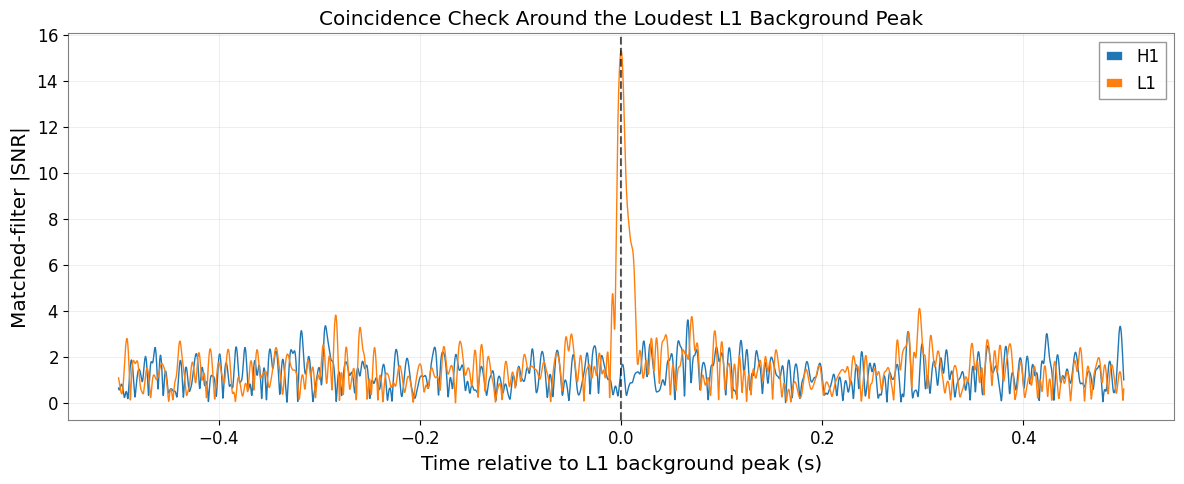

In [39]:

window_start_idx = round(
    (loud_window_start - gps_start) * sample_rate
)

snr_near_glitch = {}

for detector, data, psd in [
    ("H1", h1_long_pc, psd_h1_event),
    ("L1", l1_long_pc, psd_l1_event)
]:
    chunk = data[
        window_start_idx:window_start_idx + segment_length
    ]

    chunk = highpass(chunk, 15.0, filter_order=8)

    snr = matched_filter(
        template,
        chunk,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    snr = snr[len(snr)//4: 3*len(snr)//4]
    snr_near_glitch[detector] = snr

    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))

    local_mask = np.abs(times - loud_l1_peak_time) <= 0.1
    local_indices = np.flatnonzero(local_mask)

    if len(local_indices) == 0:
        print(f"{detector}: no samples near L1 peak")
        continue

    peak_idx = local_indices[np.argmax(values[local_mask])]

    print(f"\n{detector}")
    print("Local peak SNR:", round(float(values[peak_idx]), 3))
    print("Local peak GPS:", round(float(times[peak_idx]), 6))
    print(
        "Offset from L1 peak (ms):",
        round((float(times[peak_idx]) - loud_l1_peak_time) * 1000, 3)
    )

plt.figure(figsize=(12, 5))

for detector, snr in snr_near_glitch.items():
    times = np.asarray(snr.sample_times)
    values = np.abs(np.asarray(snr))
    relative_times = times - loud_l1_peak_time

    mask = np.abs(relative_times) <= 0.5

    plt.plot(
        relative_times[mask],
        values[mask],
        label=detector,
        linewidth=1
    )

plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.xlabel("Time relative to L1 background peak (s)")
plt.ylabel("Matched-filter |SNR|")
plt.title("Coincidence Check Around the Loudest L1 Background Peak")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [43]:
glitch_time = 1126259245.2302246

l1_glitch_segment = l1_long.crop(
    glitch_time - 8,
    glitch_time + 8
)

q_zoom = l1_glitch_segment.q_transform(
    qrange=(4, 64),
    frange=(20, 512),
    gps=glitch_time,
    search=0.5,
    outseg=(glitch_time - 0.5, glitch_time + 0.5),
    whiten=True,
    highpass=15,
    tres=0.002,
    fres=2
)



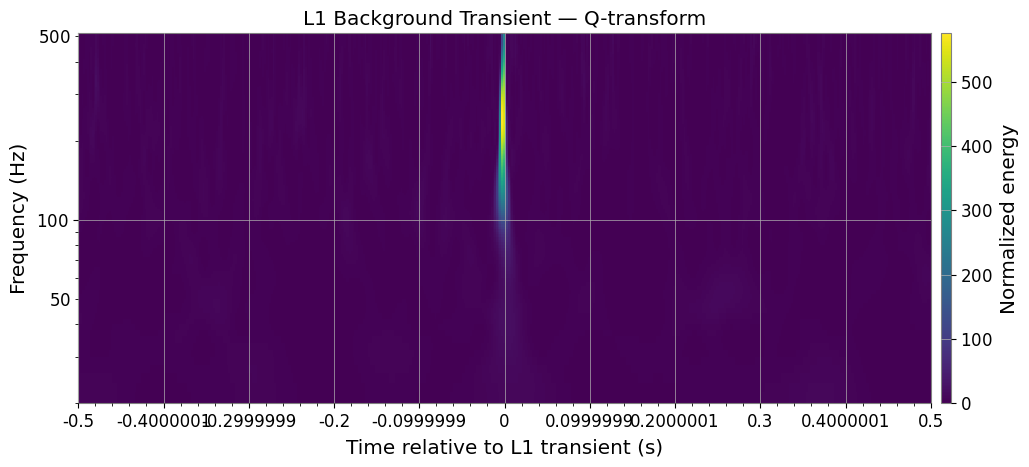

In [44]:

plot = q_zoom.plot(figsize=(11, 5))

ax = plot.gca()
ax.set_epoch(glitch_time)
ax.set_xlim(glitch_time - 0.5, glitch_time + 0.5)
ax.set_ylim(20, 512)
ax.set_yscale("log")

ax.set_xlabel("Time relative to L1 transient (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("L1 Background Transient — Q-transform")

plot.colorbar(label="Normalized energy")
plot.show()


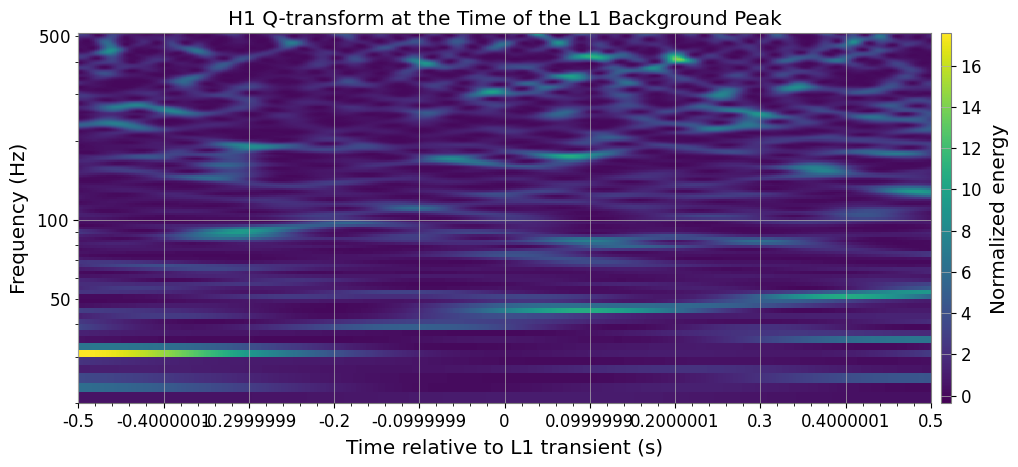

In [45]:

h1_glitch_segment = h1_long.crop(
    glitch_time - 8,
    glitch_time + 8
)

q_h1 = h1_glitch_segment.q_transform(
    qrange=(4, 64),
    frange=(20, 512),
    gps=glitch_time,
    search=0.5,
    outseg=(glitch_time - 0.5, glitch_time + 0.5),
    whiten=True,
    highpass=15,
    tres=0.002,
    fres=2
)

plot = q_h1.plot(figsize=(11, 5))
ax = plot.gca()
ax.set_epoch(glitch_time)
ax.set_xlim(glitch_time - 0.5, glitch_time + 0.5)
ax.set_ylim(20, 512)
ax.set_yscale("log")
ax.set_xlabel("Time relative to L1 transient (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("H1 Q-transform at the Time of the L1 Background Peak")
plot.colorbar(label="Normalized energy")
plot.show()


In [46]:

from gwpy.timeseries import StateVector

glitch_start = int(glitch_time) - 10
glitch_end = int(glitch_time) + 10

for detector in ["H1", "L1"]:
    print(f"\n{'=' * 12} {detector} {'=' * 12}")

    state = StateVector.fetch_open_data(
        detector,
        glitch_start,
        glitch_end
    )

    print("State-vector bits:")
    print(state.bits)

    flags = state.to_dqflags()

    for name, flag in flags.items():
        active_at_glitch = any(
            float(segment[0]) <= glitch_time < float(segment[1])
            for segment in flag.active
        )

        print(
            f"{name}:",
            "PASS / active" if active_at_glitch else "NOT PASS / inactive"
        )



============ H1 ============
State-vector bits:
Bits(0: data present
     1: passes the cbc CAT1 test
     2: passes cbc CAT2 test
     3: passes cbc CAT3 test
     4: passes burst CAT1 test
     5: passes burst CAT2 test
     6: passes burst CAT3 test,
     channel=None,
     epoch=1126256640.0)
data present: PASS / active
passes the cbc CAT1 test: PASS / active
passes cbc CAT2 test: PASS / active
passes cbc CAT3 test: PASS / active
passes burst CAT1 test: PASS / active
passes burst CAT2 test: PASS / active
passes burst CAT3 test: PASS / active

============ L1 ============
State-vector bits:
Bits(0: data present
     1: passes the cbc CAT1 test
     2: passes cbc CAT2 test
     3: passes cbc CAT3 test
     4: passes burst CAT1 test
     5: passes burst CAT2 test
     6: passes burst CAT3 test,
     channel=None,
     epoch=1126256640.0)
data present: PASS / active
passes the cbc CAT1 test: PASS / active
passes cbc CAT2 test: PASS / active
passes cbc CAT3 test: PASS / active
passes b

In [47]:

import os
import urllib.request
from gwosc.locate import get_event_urls
from gwpy.timeseries import StateVector

urls = get_event_urls("GW150914")
candidates = [
    url for url in urls
    if "L-L1_" in url and "-4096.hdf5" in url
]

if not candidates:
    raise RuntimeError("Could not find the official L1 4096-second HDF5 file.")

l1_url = candidates[0]
local_file = "/content/L1_GW150914_4096.hdf5"

if not os.path.exists(local_file):
    print("Downloading official L1 file...")
    urllib.request.urlretrieve(l1_url, local_file)

print("File ready:", local_file)

injection_state = StateVector.read(
    local_file,
    format="hdf5.gwosc",
    path="quality/injections",
    value_dataset="Injmask",
    bits_dataset="InjDescriptions"
)

print("\nInjection flags:")
print(injection_state.bits)

print("\nInjection flag status at the L1 transient:")
injection_flags = injection_state.to_dqflags()

for name, flag in injection_flags.items():
    active = any(
        float(segment[0]) <= glitch_time < float(segment[1])
        for segment in flag.active
    )
    print(f"{name}: {'PASS / active' if active else 'NOT PASS / inactive'}")


File ready: /content/L1_GW150914_4096.hdf5

Injection flags:
Bits(0: no cbc injection
     1: no burst injections
     2: no detchar injections
     3: no continuous wave injections
     4: no stoch injections,
     channel=None,
     epoch=1126256640.0)

Injection flag status at the L1 transient:
no cbc injection: PASS / active
no burst injections: PASS / active
no detchar injections: PASS / active
no continuous wave injections: NOT PASS / inactive
no stoch injections: PASS / active


In [48]:

inj_times = np.asarray(injection_state.times.value)
inj_values = np.asarray(injection_state.value, dtype=np.uint32)

window = np.abs(inj_times - glitch_time) <= 10

local_times = inj_times[window]
local_values = inj_values[window]

no_cw_injection = (local_values & (1 << 3)) != 0

inspection = pd.DataFrame({
    "GPS_Time": local_times,
    "Raw_Injection_Mask": local_values,
    "NO_CW_HW_INJ_Bit_Set": no_cw_injection
})

print("State-vector sampling rate (Hz):",
      injection_state.sample_rate.to_value("Hz"))

print("Samples inspected:", len(inspection))
print("Samples with NO_CW_HW_INJ bit set:",
      int(no_cw_injection.sum()))
print("Samples with NO_CW_HW_INJ bit unset:",
      int((~no_cw_injection).sum()))

display(inspection)


State-vector sampling rate (Hz): 1.0
Samples inspected: 20
Samples with NO_CW_HW_INJ bit set: 0
Samples with NO_CW_HW_INJ bit unset: 20


,GPS_Time,Raw_Injection_Mask,NO_CW_HW_INJ_Bit_Set
0,1.126259e+09,23,False
1,1.126259e+09,23,False
2,1.126259e+09,23,False
3,1.126259e+09,23,False
4,1.126259e+09,23,False
5,1.126259e+09,23,False
6,1.126259e+09,23,False
7,1.126259e+09,23,False
8,1.126259e+09,23,False
9,1.126259e+09,23,False


In [49]:

from pycbc.vetoes.chisq import power_chisq
from pycbc.filter import matched_filter
from pycbc.waveform import get_fd_waveform
import numpy as np
import pandas as pd

num_bins = 16
dof = 2 * num_bins - 2

template_chisq, _ = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=40,
    mass2=32,
    f_lower=20.0,
    delta_f=1.0 / 32.0
)
template_chisq.resize(4096 * 32 // 2 + 1)

def evaluate_candidate(data, psd, detector, candidate, search_center,
                       search_window=0.1):
    snr = matched_filter(
        template_chisq,
        data,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    times = np.asarray(snr.sample_times)
    snr_abs = np.abs(np.asarray(snr))

    mask = np.abs(times - search_center) <= search_window
    indices = np.flatnonzero(mask)

    if len(indices) == 0:
        raise ValueError(f"No SNR samples found for {detector} / {candidate}")

    peak_idx = indices[np.argmax(snr_abs[indices])]
    peak_time = float(times[peak_idx])
    peak_snr = float(snr_abs[peak_idx])

    chisq_ts = power_chisq(
        template_chisq,
        data,
        num_bins=num_bins,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    chi2_value = float(np.asarray(chisq_ts)[peak_idx])

    return {
        "Candidate": candidate,
        "Detector": detector,
        "Peak_GPS": peak_time,
        "Peak_SNR": peak_snr,
        "Chi2": chi2_value,
        "Degrees_of_freedom": dof,
        "Reduced_Chi2": chi2_value / dof
    }

event_results = [
    evaluate_candidate(
        h1_event_hp, psd_h1_event, "H1", "GW150914",
        trigger_time, search_window=0.1
    ),
    evaluate_candidate(
        l1_event_hp, psd_l1_event, "L1", "GW150914",
        trigger_time, search_window=0.1
    )
]

background_start_idx = round(
    (loud_window_start - gps_start) * sample_rate
)

l1_bg = highpass(
    l1_long_pc[background_start_idx:background_start_idx + segment_length],
    15.0, filter_order=8
)
h1_bg = highpass(
    h1_long_pc[background_start_idx:background_start_idx + segment_length],
    15.0, filter_order=8
)

background_results_chisq = [
    evaluate_candidate(
        h1_bg, psd_h1_event, "H1", "L1_background_transient",
        loud_l1_peak_time, search_window=0.0
    ),
    evaluate_candidate(
        l1_bg, psd_l1_event, "L1", "L1_background_transient",
        loud_l1_peak_time, search_window=0.1
    )
]

results_chisq = pd.DataFrame(
    event_results + background_results_chisq
)

display(results_chisq.round(4))


,Candidate,Detector,Peak_GPS,Peak_SNR,Chi2,Degrees_of_freedom,Reduced_Chi2
0,GW150914,H1,1.126259e+09,19.5690,34.9771,30,1.1659
1,GW150914,L1,1.126259e+09,13.5320,22.6787,30,0.7560
2,L1_background_transient,H1,1.126259e+09,1.4647,40.7015,30,1.3567
3,L1_background_transient,L1,1.126259e+09,15.3175,507.8452,30,16.9282


In [50]:

from pycbc.filter import matched_filter
from pycbc.vetoes.chisq import power_chisq
import numpy as np
import pandas as pd

num_bins = 16
dof = 2 * num_bins - 2

def evaluate_candidate_aligned(
    data, psd, detector, candidate, search_center, search_window=0.1
):

    snr_full = matched_filter(
        template_chisq,
        data,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    snr_times = np.asarray(snr_full.sample_times)
    snr_values = np.abs(np.asarray(snr_full))


    valid = np.zeros(len(snr_full), dtype=bool)
    valid[len(snr_full)//4 : 3*len(snr_full)//4] = True

    mask = valid & (np.abs(snr_times - search_center) <= search_window)
    indices = np.flatnonzero(mask)

    if len(indices) == 0:
        raise ValueError(f"No valid SNR samples for {detector} / {candidate}")

    peak_idx = indices[np.argmax(snr_values[indices])]
    peak_time = float(snr_times[peak_idx])
    peak_snr = float(snr_values[peak_idx])


    chisq_ts = power_chisq(
        template_chisq,
        data,
        num_bins=num_bins,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    chisq_times = np.asarray(chisq_ts.sample_times)
    chisq_values = np.asarray(chisq_ts)

    #
    chisq_idx = int(np.argmin(np.abs(chisq_times - peak_time)))
    time_mismatch_ms = abs(chisq_times[chisq_idx] - peak_time) * 1000

    chi2_value = float(chisq_values[chisq_idx])

    return {
        "Candidate": candidate,
        "Detector": detector,
        "Peak_GPS": peak_time,
        "Peak_SNR": peak_snr,
        "Chi2": chi2_value,
        "Degrees_of_freedom": dof,
        "Reduced_Chi2": chi2_value / dof,
        "Chi2_time_mismatch_ms": time_mismatch_ms
    }

corrected_results = [
    evaluate_candidate_aligned(
        h1_event_hp, psd_h1_event, "H1", "GW150914",
        trigger_time
    ),
    evaluate_candidate_aligned(
        l1_event_hp, psd_l1_event, "L1", "GW150914",
        trigger_time
    ),
    evaluate_candidate_aligned(
        h1_bg, psd_h1_event, "H1", "L1_background_transient",
        loud_l1_peak_time
    ),
    evaluate_candidate_aligned(
        l1_bg, psd_l1_event, "L1", "L1_background_transient",
        loud_l1_peak_time
    )
]

corrected_chisq_df = pd.DataFrame(corrected_results)
display(corrected_chisq_df.round(4))


,Candidate,Detector,Peak_GPS,Peak_SNR,Chi2,Degrees_of_freedom,Reduced_Chi2,Chi2_time_mismatch_ms
0,GW150914,H1,1.126259e+09,19.5690,34.9771,30,1.1659,0.0
1,GW150914,L1,1.126259e+09,13.5320,22.6787,30,0.7560,0.0
2,L1_background_transient,H1,1.126259e+09,3.6163,41.1689,30,1.3723,0.0
3,L1_background_transient,L1,1.126259e+09,15.3175,507.8452,30,16.9282,0.0


In [51]:

import numpy as np
import pandas as pd

def reweighted_snr(rho, reduced_chi2):
    if reduced_chi2 <= 1:
        return rho
    return rho * (
        0.5 * (1 + reduced_chi2**3)
    )**(-1/6)

reweighted_results = corrected_chisq_df.copy()

reweighted_results["Reweighted_SNR"] = [
    reweighted_snr(rho, chi2)
    for rho, chi2 in zip(
        reweighted_results["Peak_SNR"],
        reweighted_results["Reduced_Chi2"]
    )
]

display(
    reweighted_results[
        [
            "Candidate",
            "Detector",
            "Peak_SNR",
            "Reduced_Chi2",
            "Reweighted_SNR"
        ]
    ].round(4)
)


,Candidate,Detector,Peak_SNR,Reduced_Chi2,Reweighted_SNR
0,GW150914,H1,19.5690,1.1659,18.7500
1,GW150914,L1,13.5320,0.7560,13.5320
2,L1_background_transient,H1,3.6163,1.3723,3.2812
3,L1_background_transient,L1,15.3175,16.9282,4.1787


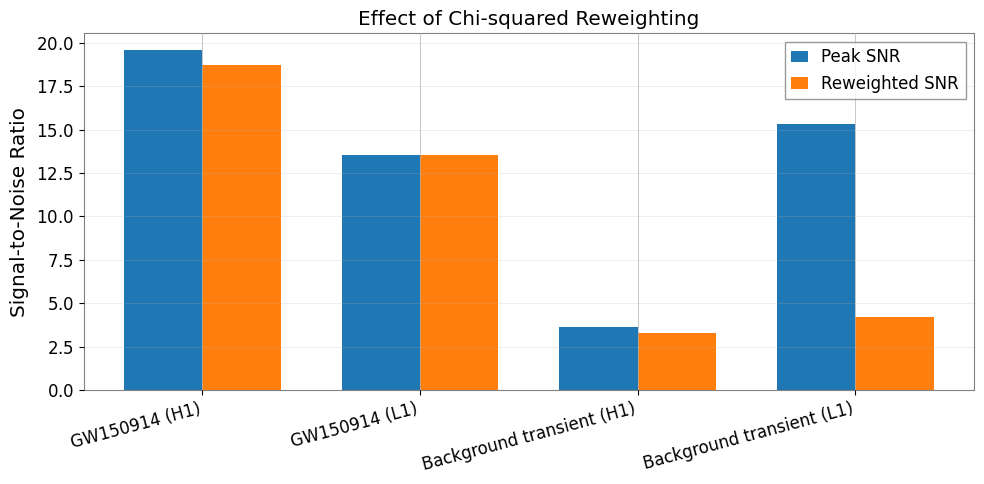

In [52]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = reweighted_results.copy()

plot_df["Label"] = (
    plot_df["Candidate"].replace({
        "GW150914": "GW150914",
        "L1_background_transient": "Background transient"
    })
    + " ("
    + plot_df["Detector"]
    + ")"
)

x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    plot_df["Peak_SNR"],
    width,
    label="Peak SNR"
)

ax.bar(
    x + width / 2,
    plot_df["Reweighted_SNR"],
    width,
    label="Reweighted SNR"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Label"], rotation=15, ha="right")
ax.set_ylabel("Signal-to-Noise Ratio")
ax.set_title("Effect of Chi-squared Reweighting")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

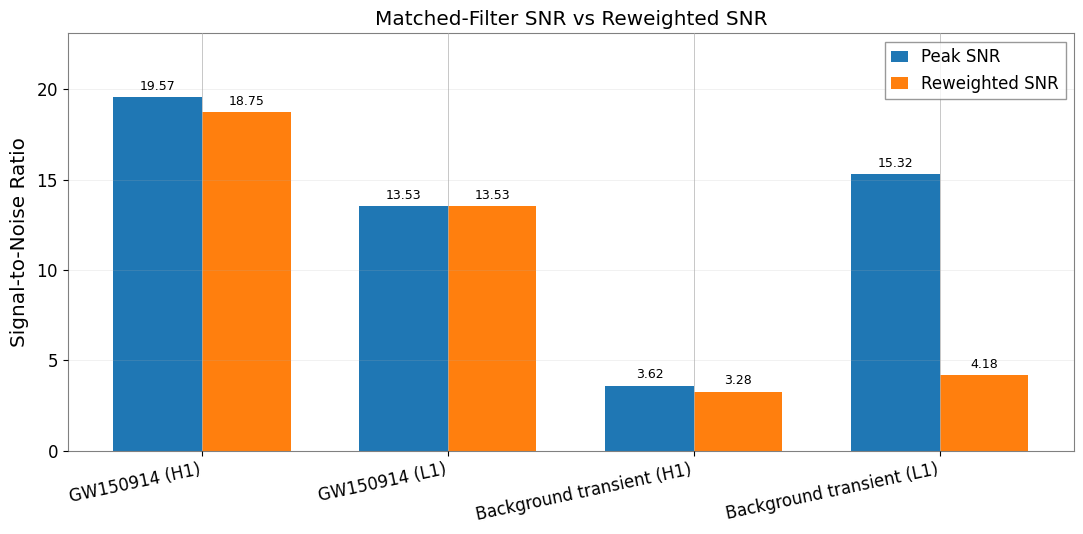

In [53]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

bars1 = ax.bar(
    x - width / 2,
    plot_df["Peak_SNR"],
    width,
    label="Peak SNR"
)

bars2 = ax.bar(
    x + width / 2,
    plot_df["Reweighted_SNR"],
    width,
    label="Reweighted SNR"
)

ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Label"], rotation=12, ha="right")
ax.set_ylabel("Signal-to-Noise Ratio")
ax.set_title("Matched-Filter SNR vs Reweighted SNR")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_ylim(0, plot_df[["Peak_SNR", "Reweighted_SNR"]].max().max() * 1.18)

plt.tight_layout()
plt.show()

In [54]:
[
    (name, type(obj).__name__, getattr(obj, "shape", None))
    for name, obj in globals().copy().items()
    if any(word in name.lower()
           for word in ["background", "offsource", "bg_results"])
]

[('background', 'ndarray', (64717,)),
 ('max_background', 'float64', ()),
 ('median_background', 'float64', ()),
 ('scan_background', 'function', None),
 ('background_h1', 'DataFrame', (251, 4)),
 ('background_l1', 'DataFrame', (251, 4)),
 ('background_results', 'DataFrame', (502, 4)),
 ('background_start_idx', 'int', None),
 ('background_results_chisq', 'list', None)]

In [55]:
print("H1 background:")
display(background_h1.head())

print("\nL1 background:")
display(background_l1.head())

print("\nColumns:")
print(background_h1.columns.tolist())

H1 background:


,Detector,Window_Start_GPS,Max_Background_SNR,Peak_GPS
0,H1,1.126257e+09,4.570855,1.126257e+09
1,H1,1.126257e+09,4.400296,1.126257e+09
2,H1,1.126257e+09,4.216599,1.126257e+09
3,H1,1.126257e+09,4.247900,1.126257e+09
4,H1,1.126257e+09,4.391701,1.126257e+09



L1 background:


,Detector,Window_Start_GPS,Max_Background_SNR,Peak_GPS
0,L1,1.126257e+09,4.796610,1.126257e+09
1,L1,1.126257e+09,4.760548,1.126257e+09
2,L1,1.126257e+09,4.946672,1.126257e+09
3,L1,1.126257e+09,4.501511,1.126257e+09
4,L1,1.126257e+09,4.843926,1.126257e+09



Columns:
['Detector', 'Window_Start_GPS', 'Max_Background_SNR', 'Peak_GPS']


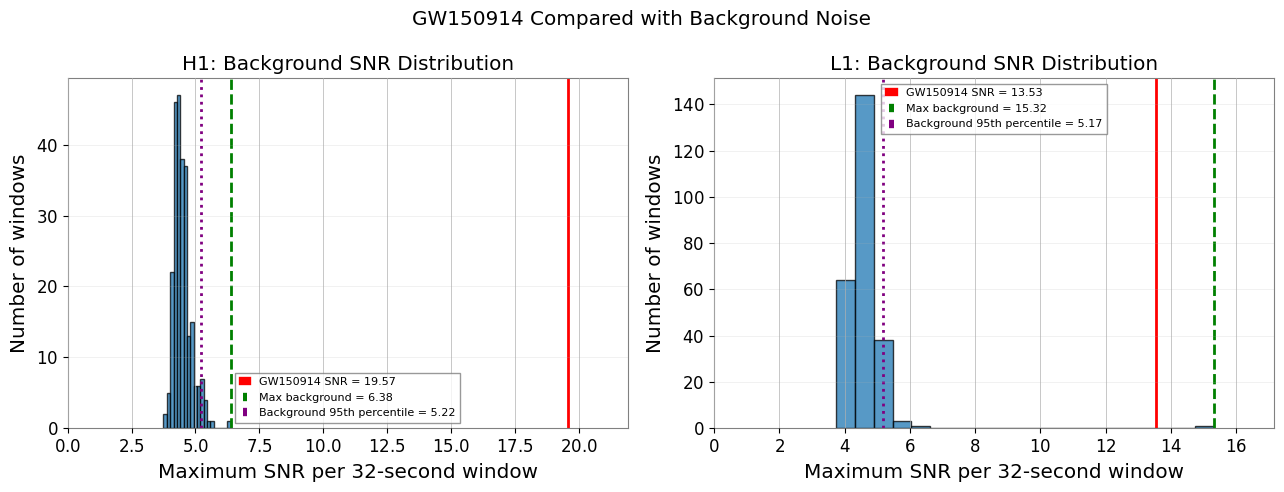

In [56]:
import matplotlib.pyplot as plt
import numpy as np

event_snr = {
    "H1": 19.569,
    "L1": 13.532
}

background_data = {
    "H1": background_h1["Max_Background_SNR"].dropna().to_numpy(),
    "L1": background_l1["Max_Background_SNR"].dropna().to_numpy()
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, detector in zip(axes, ["H1", "L1"]):
    values = background_data[detector]

    median_snr = np.median(values)
    percentile_95 = np.percentile(values, 95)
    max_snr = np.max(values)

    ax.hist(values, bins=20, edgecolor="black", alpha=0.75)

    ax.axvline(
        event_snr[detector],
        color="red",
        linestyle="-",
        linewidth=2,
        label=f"GW150914 SNR = {event_snr[detector]:.2f}"
    )

    ax.axvline(
        max_snr,
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Max background = {max_snr:.2f}"
    )

    ax.axvline(
        percentile_95,
        color="purple",
        linestyle=":",
        linewidth=2,
        label=f"Background 95th percentile = {percentile_95:.2f}"
    )

    ax.set_title(f"{detector}: Background SNR Distribution")
    ax.set_xlabel("Maximum SNR per 32-second window")
    ax.set_ylabel("Number of windows")
    ax.set_xlim(0, max(max_snr, event_snr[detector]) * 1.12)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

plt.suptitle("GW150914 Compared with Background Noise")
plt.tight_layout()
plt.show()

In [57]:
print("Type:", type(background_results_chisq))
print("Number of items:", len(background_results_chisq))

first_item = background_results_chisq[0]

print("\nFirst item type:", type(first_item))

if isinstance(first_item, pd.DataFrame):
    print("Columns:", first_item.columns.tolist())
    display(first_item.head())

elif isinstance(first_item, dict):
    print("Keys:", list(first_item.keys()))
    print(first_item)

else:
    print(repr(first_item)[:2000])

Type: <class 'list'>
Number of items: 2

First item type: <class 'dict'>
Keys: ['Candidate', 'Detector', 'Peak_GPS', 'Peak_SNR', 'Chi2', 'Degrees_of_freedom', 'Reduced_Chi2']
{'Candidate': 'L1_background_transient', 'Detector': 'H1', 'Peak_GPS': 1126259245.2302246, 'Peak_SNR': 1.4646741276938, 'Chi2': 40.70146351737365, 'Degrees_of_freedom': 30, 'Reduced_Chi2': 1.3567154505791215}


In [58]:
import pandas as pd

display(pd.DataFrame(background_results_chisq))

,Candidate,Detector,Peak_GPS,Peak_SNR,Chi2,Degrees_of_freedom,Reduced_Chi2
0,L1_background_transient,H1,1.126259e+09,1.464674,40.701464,30,1.356715
1,L1_background_transient,L1,1.126259e+09,15.317548,507.845231,30,16.928174


In [59]:
import pandas as pd
import numpy as np

def reweighted_snr(rho, reduced_chi2):
    if reduced_chi2 <= 1:
        return rho
    return rho * (0.5 * (1 + reduced_chi2**3))**(-1/6)

event_rows = corrected_chisq_df[
    corrected_chisq_df["Candidate"] == "GW150914"
].copy()

transient_rows = pd.DataFrame(background_results_chisq).copy()

comparison = pd.concat(
    [
        event_rows[
            ["Candidate", "Detector", "Peak_SNR", "Reduced_Chi2"]
        ],
        transient_rows[
            ["Candidate", "Detector", "Peak_SNR", "Reduced_Chi2"]
        ]
    ],
    ignore_index=True
)

comparison["Reweighted_SNR"] = [
    reweighted_snr(rho, chi2)
    for rho, chi2 in zip(
        comparison["Peak_SNR"],
        comparison["Reduced_Chi2"]
    )
]

display(
    comparison[
        ["Candidate", "Detector", "Peak_SNR",
         "Reduced_Chi2", "Reweighted_SNR"]
    ].round(3)
)

,Candidate,Detector,Peak_SNR,Reduced_Chi2,Reweighted_SNR
0,GW150914,H1,19.569,1.166,18.750
1,GW150914,L1,13.532,0.756,13.532
2,L1_background_transient,H1,1.465,1.357,1.334
3,L1_background_transient,L1,15.318,16.928,4.179


In [61]:
import inspect

print("Function signature:")
print(inspect.signature(scan_background))

print("\nFunction source:")
print(inspect.getsource(scan_background))

Function signature:
(data, psd, detector)

Function source:
def scan_background(data, psd, detector):
    results = []

    for start_idx in range(
        0, len(data) - segment_length + 1, stride_length
    ):
        start_gps = gps_start + start_idx / sample_rate
        end_gps = start_gps + segment_seconds

        if not (
            end_gps <= trigger_time - 16 or
            start_gps >= trigger_time + 16
        ):
            continue

        chunk = data[start_idx:start_idx + segment_length]
        chunk = highpass(chunk, 15.0, filter_order=8)

        snr = matched_filter(
            template,
            chunk,
            psd=psd,
            low_frequency_cutoff=20.0
        )

        snr = snr[len(snr)//4 : 3*len(snr)//4]

        snr_values = np.abs(np.asarray(snr))
        peak_idx = int(np.argmax(snr_values))

        results.append({
            "Detector": detector,
            "Window_Start_GPS": start_gps,
            "Max_Background_SNR": float(snr_values[

In [62]:
import numpy as np
import pandas as pd
from pycbc.vetoes.chisq import power_chisq

NUM_BINS = 16
DOF = 2 * NUM_BINS - 2

def reweighted_snr(rho, reduced_chi2):
    if reduced_chi2 <= 1:
        return rho
    return rho * (0.5 * (1 + reduced_chi2**3))**(-1/6)


def add_chisq_at_peak(background_df, data, psd):
    results = []

    for _, row in background_df.iterrows():

        start_idx = int(round(
            (row["Window_Start_GPS"] - gps_start) * sample_rate
        ))

        chunk = data[start_idx:start_idx + segment_length]

        if len(chunk) != segment_length:
            continue

        chunk = highpass(chunk, 15.0, filter_order=8)

        chisq_series = power_chisq(
            template,
            chunk,
            num_bins=NUM_BINS,
            psd=psd,
            low_frequency_cutoff=20.0
        )

        chi2_values = np.asarray(chisq_series)
        chi2_times = np.asarray(chisq_series.sample_times, dtype=float)

        peak_gps = float(row["Peak_GPS"])
        chi2_idx = int(np.argmin(np.abs(chi2_times - peak_gps)))

        chi2_value = float(np.real(chi2_values[chi2_idx]))
        reduced_chi2 = chi2_value / DOF
        rho = float(row["Max_Background_SNR"])

        results.append({
            **row.to_dict(),
            "Chi2": chi2_value,
            "Degrees_of_freedom": DOF,
            "Reduced_Chi2": reduced_chi2,
            "Reweighted_SNR": reweighted_snr(rho, reduced_chi2)
        })

    return pd.DataFrame(results)


background_h1_reweighted = add_chisq_at_peak(
    background_h1, h1_long_pc, psd_h1_event
)

background_l1_reweighted = add_chisq_at_peak(
    background_l1, l1_long_pc, psd_l1_event
)

background_reweighted = pd.concat(
    [background_h1_reweighted, background_l1_reweighted],
    ignore_index=True
)

print("Number of processed windows:", len(background_reweighted))

display(
    background_reweighted[
        [
            "Detector",
            "Window_Start_GPS",
            "Max_Background_SNR",
            "Reduced_Chi2",
            "Reweighted_SNR"
        ]
    ].head()
)

print("\nBackground summary:")
display(
    background_reweighted.groupby("Detector")["Reweighted_SNR"].agg(
        ["count", "median", "mean", "max"]
    ).round(3)
)

Number of processed windows: 502


,Detector,Window_Start_GPS,Max_Background_SNR,Reduced_Chi2,Reweighted_SNR
0,H1,1.126257e+09,4.570855,0.837320,4.570855
1,H1,1.126257e+09,4.400296,1.805238,3.581156
2,H1,1.126257e+09,4.216599,1.556387,3.647926
3,H1,1.126257e+09,4.247900,0.944210,4.247900
4,H1,1.126257e+09,4.391701,1.069542,4.314851



Background summary:


,count,median,mean,max
Detector,,,,
H1,251,4.260,4.270,5.493
L1,251,4.186,4.146,5.713


H1: 0 of 251 background windows have Reweighted SNR >= GW150914
L1: 0 of 251 background windows have Reweighted SNR >= GW150914


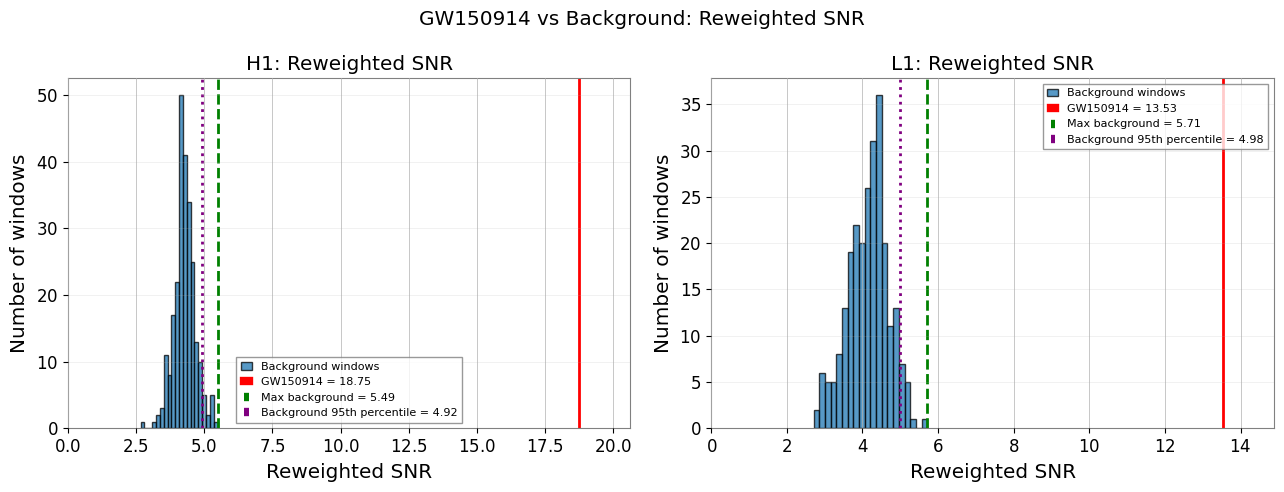

In [63]:
import matplotlib.pyplot as plt
import numpy as np

event_reweighted_snr = {
    "H1": 18.750,
    "L1": 13.532
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, detector in zip(axes, ["H1", "L1"]):
    values = background_reweighted.loc[
        background_reweighted["Detector"] == detector,
        "Reweighted_SNR"
    ].dropna().to_numpy()

    event_snr = event_reweighted_snr[detector]
    max_bg = np.max(values)
    percentile_95 = np.percentile(values, 95)

    ax.hist(
        values,
        bins=20,
        edgecolor="black",
        alpha=0.75,
        label="Background windows"
    )

    ax.axvline(
        event_snr,
        color="red",
        linewidth=2,
        label=f"GW150914 = {event_snr:.2f}"
    )

    ax.axvline(
        max_bg,
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Max background = {max_bg:.2f}"
    )

    ax.axvline(
        percentile_95,
        color="purple",
        linestyle=":",
        linewidth=2,
        label=f"Background 95th percentile = {percentile_95:.2f}"
    )

    exceedances = np.sum(values >= event_snr)

    ax.set_title(f"{detector}: Reweighted SNR")
    ax.set_xlabel("Reweighted SNR")
    ax.set_ylabel("Number of windows")
    ax.set_xlim(0, event_snr * 1.10)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

    print(
        f"{detector}: {exceedances} of {len(values)} "
        f"background windows have Reweighted SNR >= GW150914"
    )

plt.suptitle("GW150914 vs Background: Reweighted SNR")
plt.tight_layout()
plt.show()

In [64]:
import numpy as np
import pandas as pd
from pycbc.filter import matched_filter
from pycbc.vetoes.chisq import power_chisq

NUM_BINS = 16
DOF = 2 * NUM_BINS - 2

def max_reweighted_in_window(chunk, psd):
    chunk = highpass(chunk, 15.0, filter_order=8)

    snr = matched_filter(
        template, chunk, psd=psd,
        low_frequency_cutoff=20.0
    )

    chisq = power_chisq(
        template, chunk,
        num_bins=NUM_BINS,
        psd=psd,
        low_frequency_cutoff=20.0
    )

    rho = np.abs(np.asarray(snr))
    snr_times = np.asarray(snr.sample_times, dtype=float)

    chi2 = np.real(np.asarray(chisq))
    chi_times = np.asarray(chisq.sample_times, dtype=float)

    idx = np.searchsorted(chi_times, snr_times)
    left = np.clip(idx - 1, 0, len(chi_times) - 1)
    right = np.clip(idx, 0, len(chi_times) - 1)

    nearest = np.where(
        np.abs(chi_times[left] - snr_times)
        <= np.abs(chi_times[right] - snr_times),
        left, right
    )

    reduced = chi2[nearest] / DOF

    rho_hat = rho.copy()
    mask = reduced > 1
    rho_hat[mask] *= (
        0.5 * (1 + reduced[mask]**3)
    )**(-1/6)

    start = float(chunk.start_time)
    valid = (
        (snr_times >= start + segment_seconds / 4)
        & (snr_times < start + 3 * segment_seconds / 4)
    )

    valid_indices = np.flatnonzero(valid)
    if len(valid_indices) == 0:
        raise ValueError("No valid central samples in this window.")

    best_idx = valid_indices[np.argmax(rho_hat[valid])]

    return {
        "Max_Reweighted_SNR": float(rho_hat[best_idx]),
        "Peak_GPS": float(snr_times[best_idx]),
        "SNR_at_peak": float(rho[best_idx]),
        "Reduced_Chi2_at_peak": float(reduced[best_idx])
    }


def scan_reweighted_background(df, data, psd):
    results = []

    for _, row in df.iterrows():
        start_idx = int(round(
            (row["Window_Start_GPS"] - gps_start) * sample_rate
        ))

        chunk = data[start_idx:start_idx + segment_length]

        result = max_reweighted_in_window(chunk, psd)

        results.append({
            "Detector": row["Detector"],
            "Window_Start_GPS": row["Window_Start_GPS"],
            **result
        })

    return pd.DataFrame(results)


bg_h1_final = scan_reweighted_background(
    background_h1, h1_long_pc, psd_h1_event
)

bg_l1_final = scan_reweighted_background(
    background_l1, l1_long_pc, psd_l1_event
)

bg_final = pd.concat([bg_h1_final, bg_l1_final], ignore_index=True)

event_final = pd.DataFrame([
    {
        "Candidate": "GW150914",
        "Detector": "H1",
        **max_reweighted_in_window(h1_event_pc, psd_h1_event)
    },
    {
        "Candidate": "GW150914",
        "Detector": "L1",
        **max_reweighted_in_window(l1_event_pc, psd_l1_event)
    }
])

display(event_final.round(4))

for detector in ["H1", "L1"]:
    bg_values = bg_final.loc[
        bg_final["Detector"] == detector,
        "Max_Reweighted_SNR"
    ].dropna()

    event_value = float(
        event_final.loc[
            event_final["Detector"] == detector,
            "Max_Reweighted_SNR"
        ].iloc[0]
    )

    print(
        f"{detector}: Event = {event_value:.3f} | "
        f"Max background = {bg_values.max():.3f} | "
        f"Background windows >= event = "
        f"{int((bg_values >= event_value).sum())}/{len(bg_values)}"
    )

,Candidate,Detector,Max_Reweighted_SNR,Peak_GPS,SNR_at_peak,Reduced_Chi2_at_peak
0,GW150914,H1,18.750,1.126259e+09,19.569,1.1659
1,GW150914,L1,13.532,1.126259e+09,13.532,0.7560


H1: Event = 18.750 | Max background = 5.493 | Background windows >= event = 0/251
L1: Event = 13.532 | Max background = 5.966 | Background windows >= event = 0/251


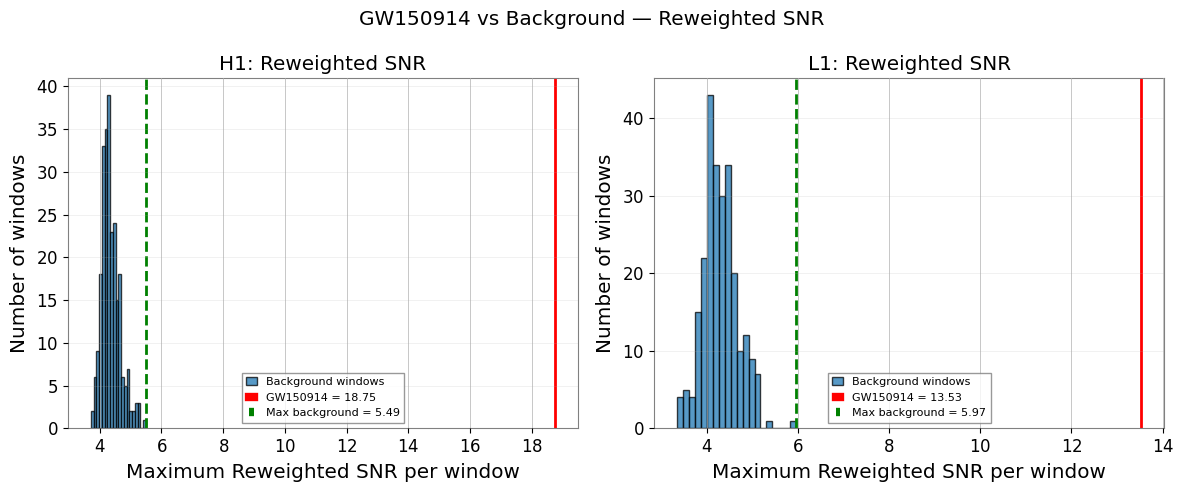

In [65]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, detector in zip(axes, ["H1", "L1"]):

    bg_values = bg_final.loc[
        bg_final["Detector"] == detector,
        "Max_Reweighted_SNR"
    ].dropna().to_numpy()

    event_value = float(
        event_final.loc[
            event_final["Detector"] == detector,
            "Max_Reweighted_SNR"
        ].iloc[0]
    )

    max_bg = np.max(bg_values)

    ax.hist(
        bg_values,
        bins=20,
        edgecolor="black",
        alpha=0.75,
        label="Background windows"
    )

    ax.axvline(
        event_value,
        color="red",
        linewidth=2,
        label=f"GW150914 = {event_value:.2f}"
    )

    ax.axvline(
        max_bg,
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Max background = {max_bg:.2f}"
    )

    ax.set_title(f"{detector}: Reweighted SNR")
    ax.set_xlabel("Maximum Reweighted SNR per window")
    ax.set_ylabel("Number of windows")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

plt.suptitle("GW150914 vs Background — Reweighted SNR")
plt.tight_layout()
plt.show()